# 04 Evaluation

PLAN.md step 5, on held-out (test-match) predictions only. Logic is in `src/passmodel/evaluate.py`; `scripts/run_pipeline.py` writes the `results/step5_*` files this notebook reads.

In [1]:
import pandas as pd
from IPython.display import Image
from passmodel.load import REPO_ROOT

RESULTS = REPO_ROOT / "results"
read = lambda name, **kw: pd.read_csv(RESULTS / f"{name}.csv", **kw)

## Metrics per fold, with 95% bootstrap CIs
Resampling test passes 1,000 times. `delta_log_loss` = model minus logistic baseline on the same resample (negative = better than the baseline).

In [2]:
ci = read("step5_bootstrap_ci")
ci.pivot_table(index=["metric", "model"], columns="fold", values="estimate")

fold                                                         1       2       3
metric         model                                                          
brier          constant                                 0.1904  0.1507  0.1647
               logistic (pass length)                   0.1887  0.1504  0.1639
               logistic (pitch control)                 0.1870  0.1516  0.1589
               xgboost (single target + pitch control)  0.1661  0.1339  0.1476
               xgboost (single target)                  0.1678  0.1327  0.1461
               xgboost (target mixture)                 0.1642  0.1299  0.1454
delta_log_loss constant                                 0.0046  0.0010  0.0018
               logistic (pass length)                   0.0000  0.0000  0.0000
               logistic (pitch control)                -0.0047  0.0008 -0.0144
               xgboost (single target + pitch control) -0.0504 -0.0577 -0.0489
               xgboost (single target)                 -0.0463 -0.0604 -0.0552
               xgboost (target mixture)                -0.0627 -0.0672 -0.0589
log_loss       constant                                 0.5710  0.4800  0.5111
               logistic (pass length)                   0.5664  0.4790  0.5093
               logistic (pitch control)                 0.5618  0.4798  0.4949
               xgboost (single target + pitch control)  0.5160  0.4213  0.4604
               xgboost (single target)                  0.5201  0.4186  0.4541
               xgboost (target mixture)                 0.5037  0.4118  0.4504
roc_auc        constant                                 0.5000  0.5000  0.5000
               logistic (pass length)                   0.5718  0.5534  0.5542
               logistic (pitch control)                 0.6260  0.5846  0.6632
               xgboost (single target + pitch control)  0.7287  0.7431  0.7313
               xgboost (single target)                  0.7273  0.7481  0.7414
               xgboost (target mixture)                 0.7301  0.7615  0.7462

In [3]:
ci[ci["metric"] == "delta_log_loss"]

,model,fold,metric,estimate,ci_low,ci_high
3,constant,1,delta_log_loss,0.0046,-0.0002,0.0092
7,logistic (pass length),1,delta_log_loss,0.0000,0.0000,0.0000
11,logistic (pitch control),1,delta_log_loss,-0.0047,-0.0148,0.0058
15,xgboost (single target + pitch control),1,delta_log_loss,-0.0504,-0.0797,-0.0221
19,xgboost (single target),1,delta_log_loss,-0.0463,-0.0763,-0.0176
23,xgboost (target mixture),1,delta_log_loss,-0.0627,-0.0877,-0.0388
27,constant,2,delta_log_loss,0.0010,-0.0035,0.0054
31,logistic (pass length),2,delta_log_loss,0.0000,0.0000,0.0000
35,logistic (pitch control),2,delta_log_loss,0.0008,-0.0089,0.0109
39,xgboost (single target + pitch control),2,delta_log_loss,-0.0577,-0.0794,-0.0347


## Calibration (all three held-out matches pooled, 10 equal-count bins)

In [4]:
read("step5_calibration")

,mean_predicted,observed_rate,n
0,0.4268,0.4716,335
1,0.6357,0.6497,334
2,0.7259,0.6916,334
3,0.7812,0.7731,335
4,0.8205,0.7994,334
5,0.8531,0.8174,334
6,0.8799,0.8836,335
7,0.9064,0.8922,334
8,0.9363,0.9311,334
9,0.9688,0.9761,335


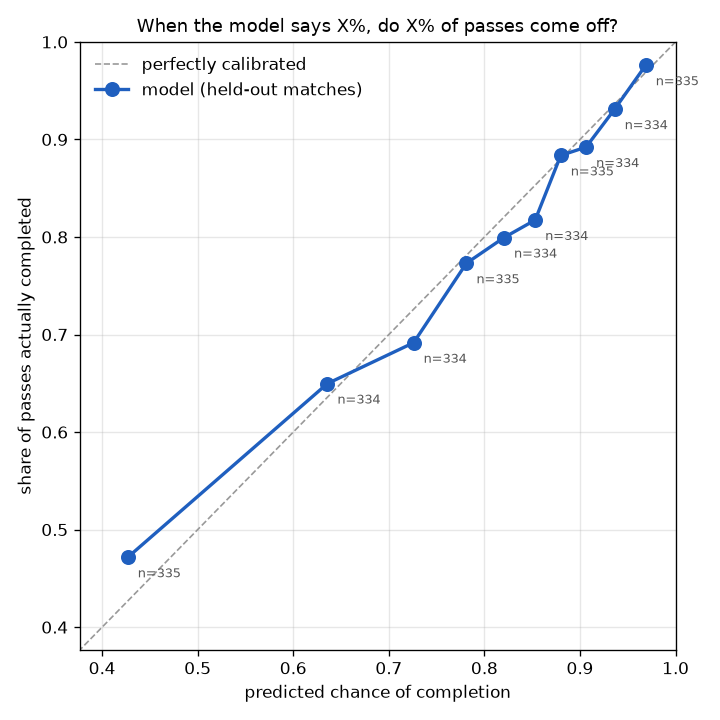

In [5]:
Image(RESULTS / "figures" / "calibration.png")

## SHAP (held-out passes, log-odds)

In [6]:
read("step5_shap_importance", index_col=0).head(10)

,mean_abs_shap
start_x,0.3462
passer_nearest_opp,0.2811
target_nearest_opp,0.2517
passer_speed,0.1866
lane_min_opp_dist,0.1740
start_y,0.1607
passer_nearest_opp_speed,0.1260
target_confidence,0.1078
is_header,0.0936
target_closing_speed,0.0808


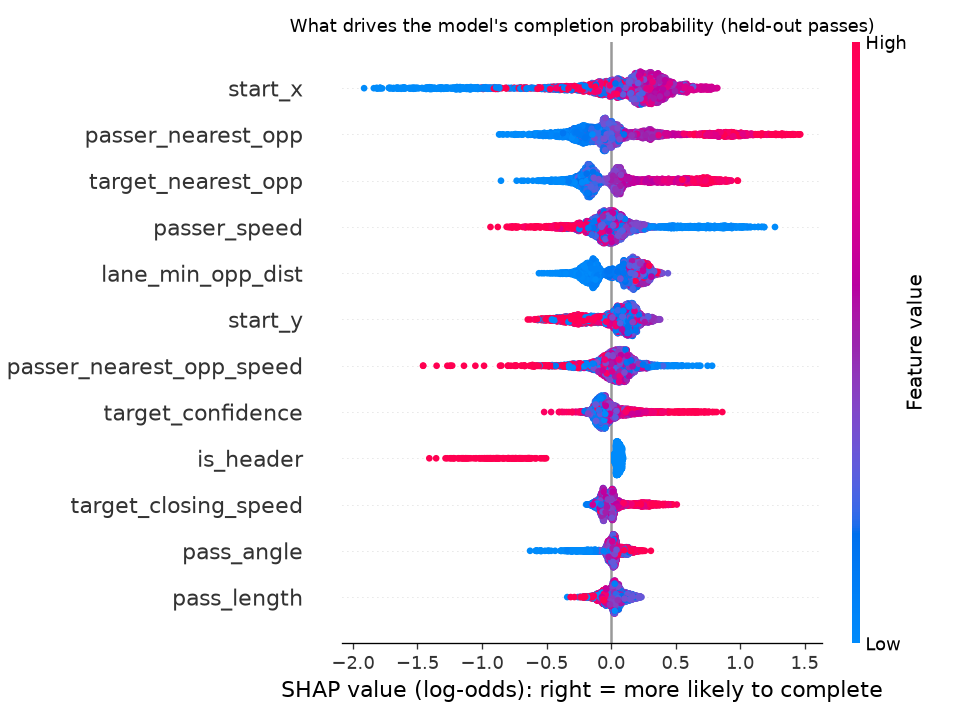

In [7]:
Image(RESULTS / "figures" / "shap_summary.png")

## Ablation: XGBoost refitted without each feature group
Positive delta = held-out log loss got worse without the group. Reported only; the headline model is not changed by this (that would be choosing features on the test matches).

In [8]:
read("step5_ablation", index_col=0)

,delta_log_loss_fold_1,delta_log_loss_fold_2,delta_log_loss_fold_3,delta_log_loss_fold_mean,folds_worse_without
model,,,,,
without location,0.0276,0.0138,0.0054,0.0156,3
without target,0.0063,0.0045,0.0090,0.0066,3
without event,0.0109,0.0077,-0.0008,0.0059,2
without geometry,0.0073,0.0031,0.0013,0.0039,3
without speed,0.0037,0.0051,0.0025,0.0038,3
without pressure,-0.0020,0.0077,-0.0013,0.0015,1
without lane,0.0023,-0.0004,-0.0015,0.0002,1


In [9]:
read("step5_ablation_ci").pivot(index="model", columns="fold", values=["estimate", "ci_low", "ci_high"])

estimate                  ci_low                 ci_high  \
fold                    1       2       3       1       2       3       1   
model                                                                       
without event      0.0109  0.0076 -0.0008  0.0028  0.0005 -0.0071  0.0188   
without geometry   0.0073  0.0031  0.0013  0.0025 -0.0007 -0.0022  0.0123   
without lane       0.0023 -0.0004 -0.0015 -0.0025 -0.0039 -0.0045  0.0076   
without location   0.0276  0.0138  0.0054  0.0122  0.0010 -0.0069  0.0422   
without pressure  -0.0020  0.0077 -0.0013 -0.0099  0.0021 -0.0068  0.0065   
without speed      0.0038  0.0051  0.0025 -0.0084 -0.0048 -0.0055  0.0161   
without target     0.0064  0.0045  0.0090 -0.0013 -0.0004  0.0036  0.0140   

                                  
fold                   2       3  
model                             
without event     0.0145  0.0068  
without geometry  0.0069  0.0052  
without lane      0.0030  0.0018  
without location  0.0265  0.0179  
without pressure  0.0132  0.0043  
without speed     0.0137  0.0108  
without target    0.0099  0.0145